# Turtle Games: Advanced Analytics for Organisational Impact

## Context
Turtle Games is a global game manufacturer and retailer that produces and sells its products and those from other companies. Their diverse product range includes books, board games, video games, and toys. The company collects extensive sales and customer review data to enhance overall sales performance by analyzing customer trends. 

## Project Objective
This project addresses three business questions:
1. How do customers engage with and accumulate loyalty points?
2. How can customers be grouped into meaningful segments for targeted marketing?
3. How to identify customer reviews to inform marketing strategies and business improvements?

## Stakeholders

The insights generated by this project can benefit several stakeholders:

* **Marketing team:** Customer segments and loyalty point drivers can help the marketing team design targeted campaigns, tailor promotions to each customer group, and focus spending on the customers most likely to engage and accumulate loyalty points.
* **Product team:** Sentiment and recurring themes from customer reviews can help the product team identify common pain points, understand what customers value in existing products, and prioritise improvements to the product range.

## Data Dictionary

| Field | Description |
| --- | --- |
| gender | Gender of the customer |
| age | Age of the customer in years |
| remuneration (k£) | Annual income of the customer in thousands of British Pounds |
| spending_score (1-100) | Score from 1 to 100 assigned to the customer based on their spending behaviour |
| loyalty_points | Total loyalty points accumulated by the customer based on purchase value |
| education | Highest education level attained by the customer |
| language | Language in which the customer review was written |
| platform | Platform on which the customer review was submitted |
| product | Unique product code of the item being reviewed |
| review | Full written review provided by the customer |
| summary | Short summary of the customer's review |

## Exploratory Data Analysis 

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Load the dataset
df = pd.read_csv("data/turtle_reviews.csv")
df.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   str    
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   str    
 6   language                2000 non-null   str    
 7   platform                2000 non-null   str    
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   str    
 10  summary                 2000 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 172.0 KB


All 11 columns are fully populated with 2,000 non-null entries each, so no missing value treatment is required. However, `product` is stored as an integer even though it represents a product code, so it should be treated as a categorical identifier rather than a numeric feature.

In [4]:
# Check for missing values
df.isna().sum()

gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0
loyalty_points            0
education                 0
language                  0
platform                  0
product                   0
review                    0
summary                   0
dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,39.49500,13.573212,17.0,29.00,38.00,49.00,72.00
remuneration (k£),2000.0,48.07906,23.123984,12.3,30.34,47.15,63.96,112.34
spending_score (1-100),2000.0,50.00000,26.094702,1.0,32.00,50.00,73.00,99.00
loyalty_points,2000.0,1578.03200,1283.239705,25.0,772.00,1276.00,1751.25,6847.00
product,2000.0,4320.52150,3148.938839,107.0,1589.25,3624.00,6654.00,11086.00


`.describe()` shows that all numeric values fall within valid ranges, with no negative or impossible entries.

In [6]:
# Check for duplicate records
print('Duplicate rows:', df.duplicated().sum())

# Identify duplicates
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

Duplicate rows: 0


,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary


In [7]:
# Rename the column headers.
df = df.rename(columns = {
    'remuneration (k£)': 'remuneration',
    'spending_score (1-100)': 'spending_score'})

# Verify the changes
df.columns

Index(['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points',
       'education', 'language', 'platform', 'product', 'review', 'summary'],
      dtype='str')

## Univariate Analysis

### Bar Chart

In [8]:
def plot_bar(df, col, title=None, figsize=(10, 6), rotation=45):
    """Plot a count bar chart for a categorical column, with counts shown above each bar."""
    sns.set_style("whitegrid")

    plt.figure(figsize=figsize)
    ax = sns.countplot(x=col, data=df, order=df[col].value_counts().index)

    label = col.replace('_', ' ').title()
    ax.set_title(title or f'Count of {label}')
    ax.set_xlabel(label)
    ax.set_ylabel('Count')
    plt.xticks(rotation=rotation)

    # Annotate the bars with the frequency count
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.0f'),
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points')

    plt.show()

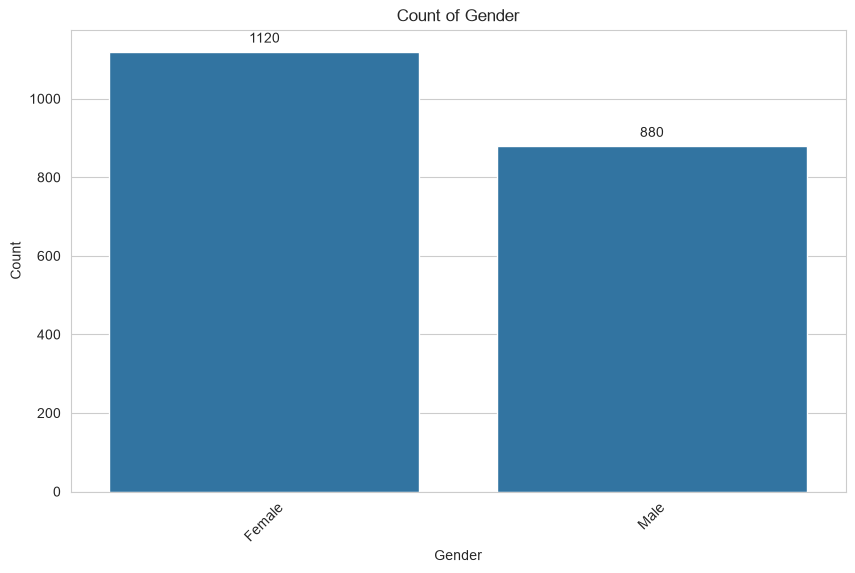

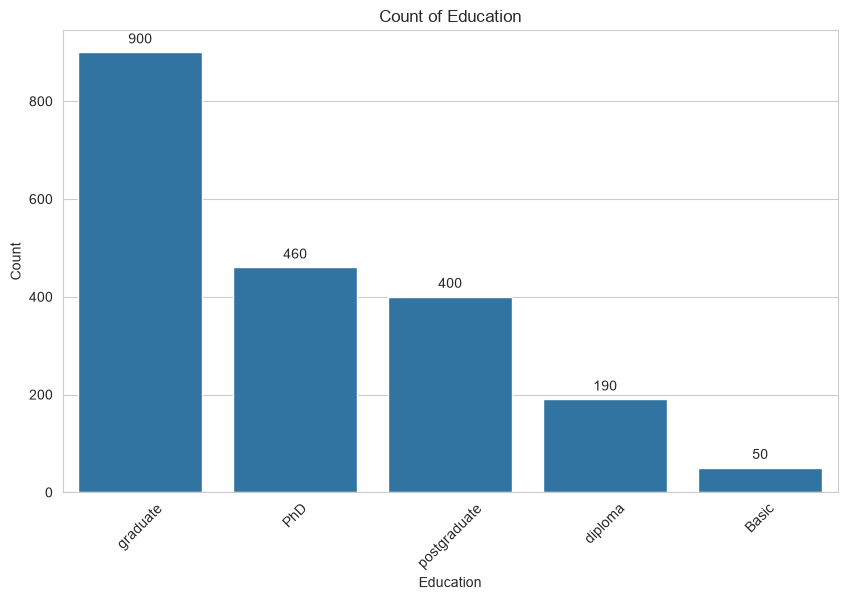

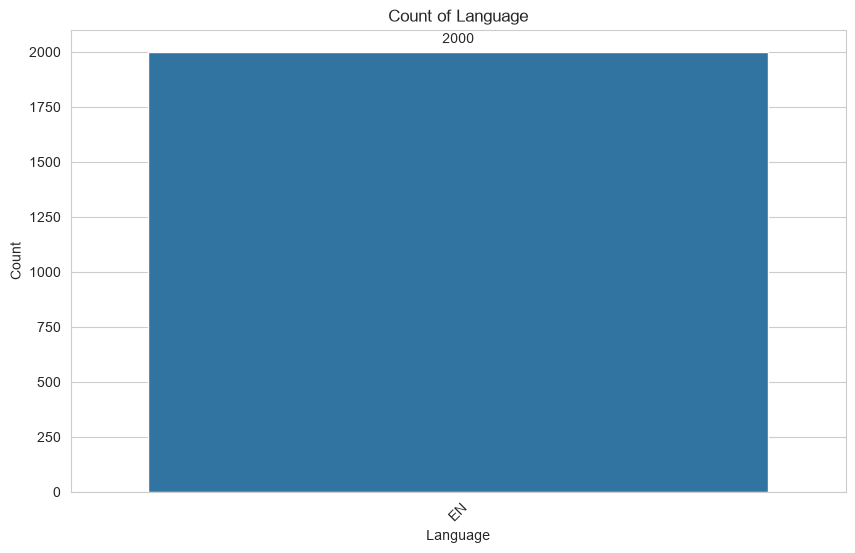

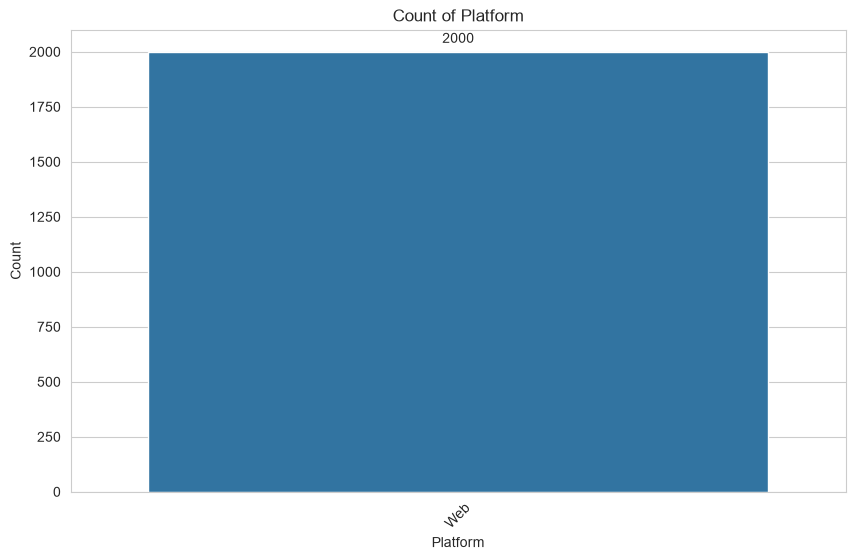

In [9]:
cat_features = ['gender', 'education', 'language', 'platform']

for feature in cat_features:
    plot_bar(df, feature)

**Gender**: The customer base leans slightly with 'Female' customers being the more common group, followed by 'Male' customers.

**Education**: The most common education levels are the higher qualifications, with 'graduate' being the most common, followed by 'PhD' and 'postgraduate'. In comparison, 'diploma' and 'Basic' are much less common in the dataset. I also noticed an inconsistency in the formatting of the category labels, where 'Basic' and 'PhD' are capitalised while 'graduate', 'postgraduate' and 'diploma' are in lowercase. These labels will be standardised during data cleaning to keep the categories consistent.

**Language**: All 2,000 reviews are written in English. As this feature has only one value, it provides no variation and will be dropped from further analysis.

**Platform**: All 2,000 reviews were submitted through the Web platform. Similar to `language`, this feature has only one value and will be dropped from further analysis.

In [10]:
# Standardise 'graduate', 'postgraduate' and 'diploma' in the 'education' column
df['education'] = df['education'].replace({'graduate': 'Graduate', 'postgraduate': 'Postgraduate', 'diploma': 'Diploma'})

### Histogram

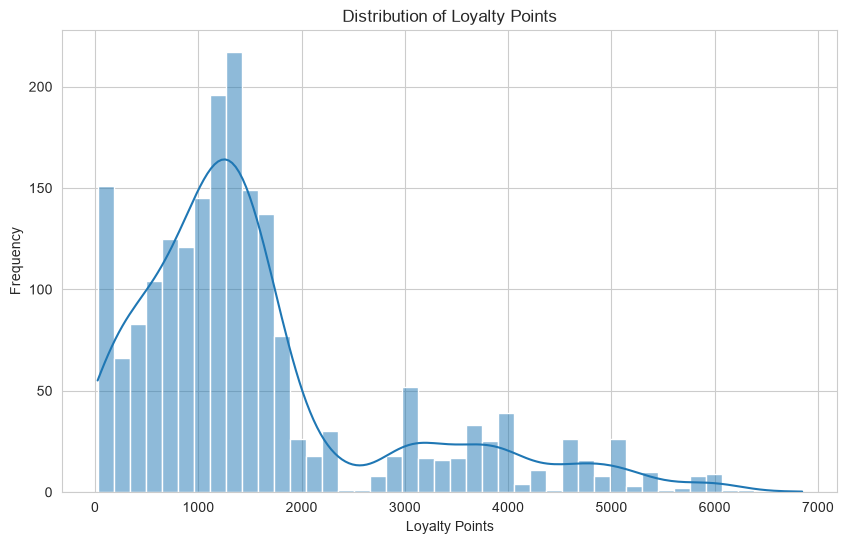

In [11]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for resale price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['loyalty_points'], kde=True)  
plt.title('Distribution of Loyalty Points')  
plt.xlabel('Loyalty Points')  
plt.ylabel('Frequency')  
plt.show()

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,39.49500,13.573212,17.0,29.00,38.00,49.00,72.00
remuneration,2000.0,48.07906,23.123984,12.3,30.34,47.15,63.96,112.34
spending_score,2000.0,50.00000,26.094702,1.0,32.00,50.00,73.00,99.00
loyalty_points,2000.0,1578.03200,1283.239705,25.0,772.00,1276.00,1751.25,6847.00
product,2000.0,4320.52150,3148.938839,107.0,1589.25,3624.00,6654.00,11086.00


The distribution of loyalty points is right-skewed, with points ranging from 25 to 6,847. The mean is approximately 1,578, while the median is 1,276. Since the mean is higher than the median, this suggests that a small group of customers with very high loyalty points is pulling the average upwards. 

Most customers hold between 0 and 2,000 points, but there is a noticeable gap around 2,500, after which a smaller second group of customers sits between roughly 3,000 and 6,000 points.

## Bivariate Analysis

### Box Plot

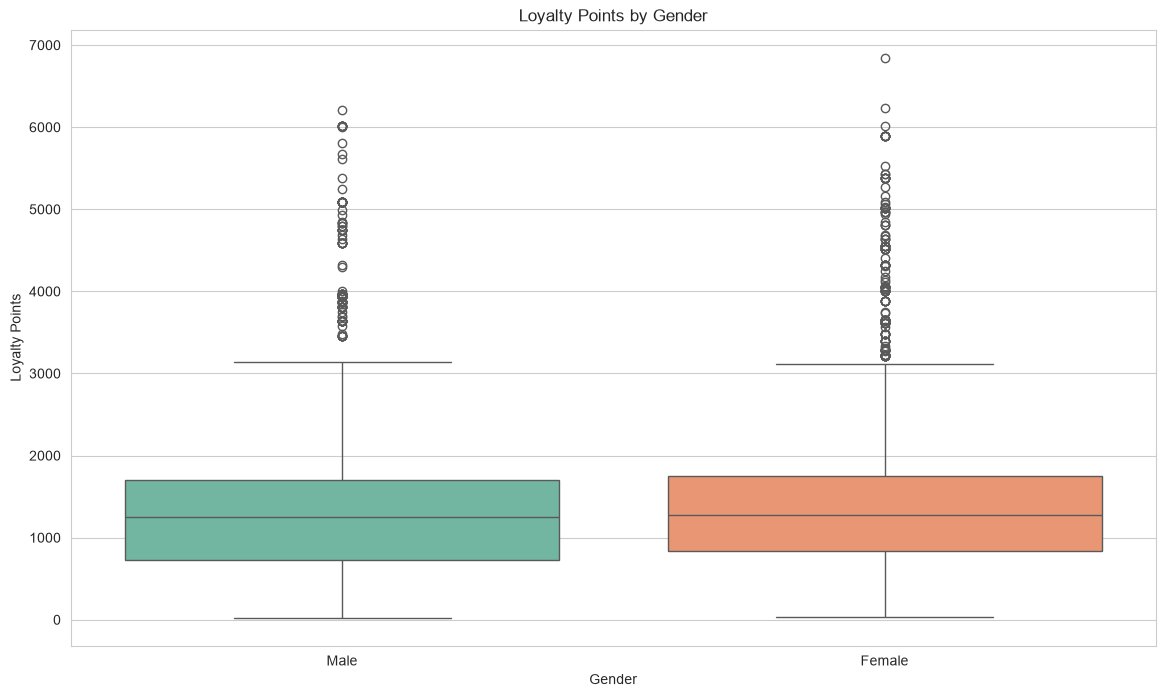

In [13]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Box plot for flat_type vs resale_price  
plt.figure(figsize=(14, 8))  
sns.boxplot(x='gender', y='loyalty_points', data=df, hue='gender', palette='Set2')  
plt.title('Loyalty Points by Gender')
plt.xlabel('Gender')
plt.ylabel('Loyalty Points')
plt.xticks(rotation=0)
plt.show()

Both genders have similar median loyalty points and a similar interquartile range (IQR) spread. However, there appear to be more outliers among female customers than male customers, representing customers with exceptionally high loyalty points above roughly 3,100.

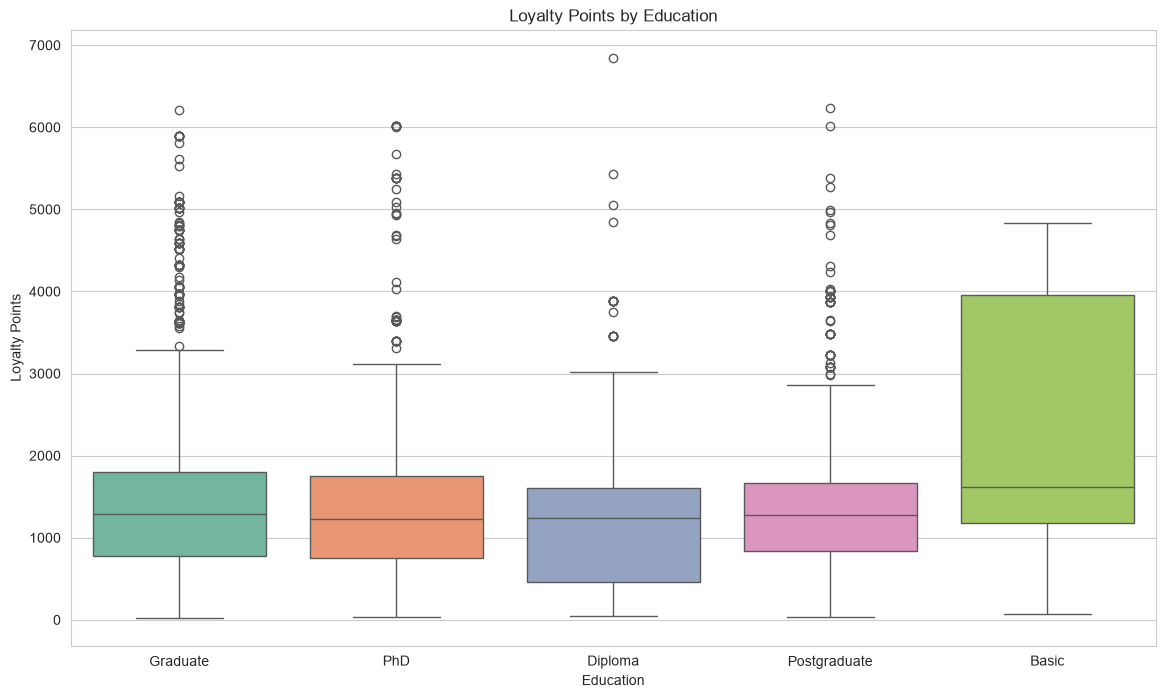

In [14]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Box plot for flat_type vs resale_price  
plt.figure(figsize=(14, 8))  
sns.boxplot(x='education', y='loyalty_points', data=df, hue='education', palette='Set2')  
plt.title('Loyalty Points by Education')
plt.xlabel('Education')
plt.ylabel('Loyalty Points')
plt.xticks(rotation=0)
plt.show()

The overall distribution of loyalty points is fairly similar across most education levels. 'Graduate', 'PhD', 'Diploma' and 'Postgraduate' customers show comparable distributions, with most customers holding fewer than 2,000 points. In contrast, 'Basic' customers have a noticeably higher and much wider distribution of loyalty points.

The median loyalty points are almost identical for 'Graduate', 'Postgraduate', 'Diploma' and 'PhD' customers. 'Basic' customers have the highest median, suggesting that this group tends to accumulate more loyalty points than the others.

Looking at the interquartile range (IQR), 'Basic' customers show the greatest variation in loyalty points compared to the other groups. 'Postgraduate' customers are the most consistent with the narrowest IQR, while 'Diploma' customers have the lowest first quartile, meaning a larger share of this group holds relatively few points.

There is the presence of outliers for 'Graduate', 'PhD', 'Diploma' and 'Postgraduate' customers, representing customers with exceptionally high loyalty points above roughly 3,000. No outliers are flagged for 'Basic' customers, but this is because its wide IQR stretches the whiskers up to the top of its range rather than because the group has no high-point customers.

However, as the 'Basic' group contains only 2.5% of the dataset, its results should be interpreted with caution, as a small number of customers can heavily influence its distribution.

### Scatter Plot

In [15]:
def plot_scatter(df, x, y='loyalty_points'):
    """Plot a scatter of a numeric feature against loyalty points, with a best-fit line."""
    # Set the aesthetic style of the plots
    sns.set_style("whitegrid")

    x_label = x.replace('_', ' ').title()
    y_label = y.replace('_', ' ').title()

    # Scatter plot with a best-fit line
    plt.figure(figsize=(12, 8))
    sns.regplot(x=x, y=y, data=df,
                scatter_kws={'alpha': 0.7},
                line_kws={'color': 'red'})
    plt.title(f'Scatter Plot of {x_label} vs {y_label}')
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.show()

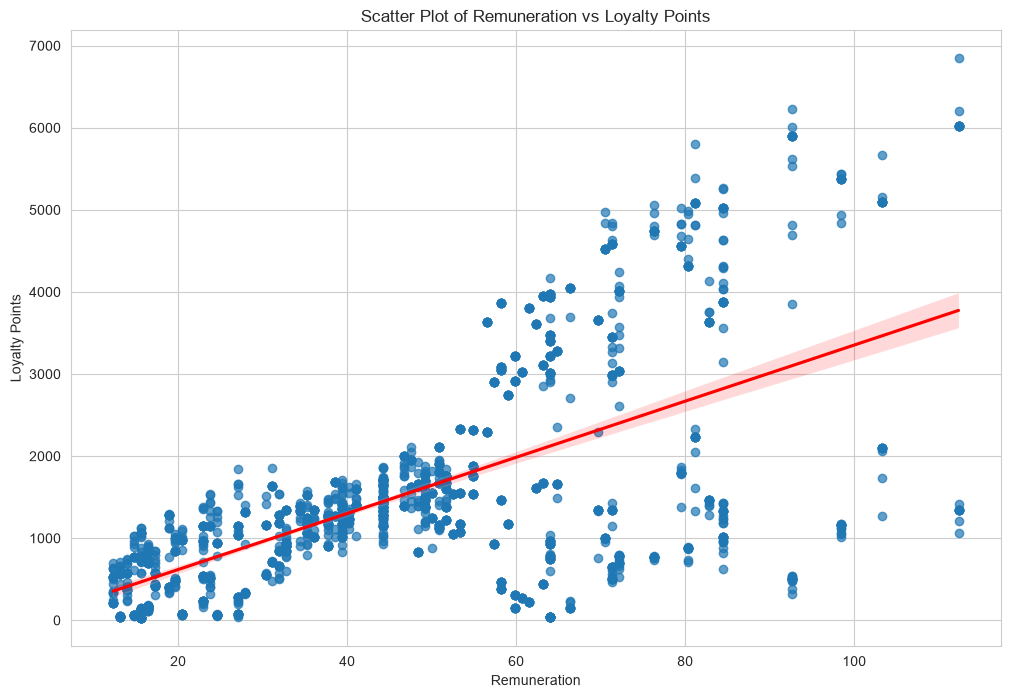

In [16]:
plot_scatter(df, 'remuneration')

There is a positive trend indicating that as remuneration increases, loyalty points generally increase. This trend suggests that customers with higher incomes tend to accumulate more loyalty points. 

However, the relationship weakens beyond a remuneration of around £55k, where loyalty points split into two distinct groups: one with high loyalty points (roughly 3,000 to 6,000) and another with low loyalty points (below 2,500). This suggests that remuneration alone may not fully explain how many loyalty points a customer accumulates.

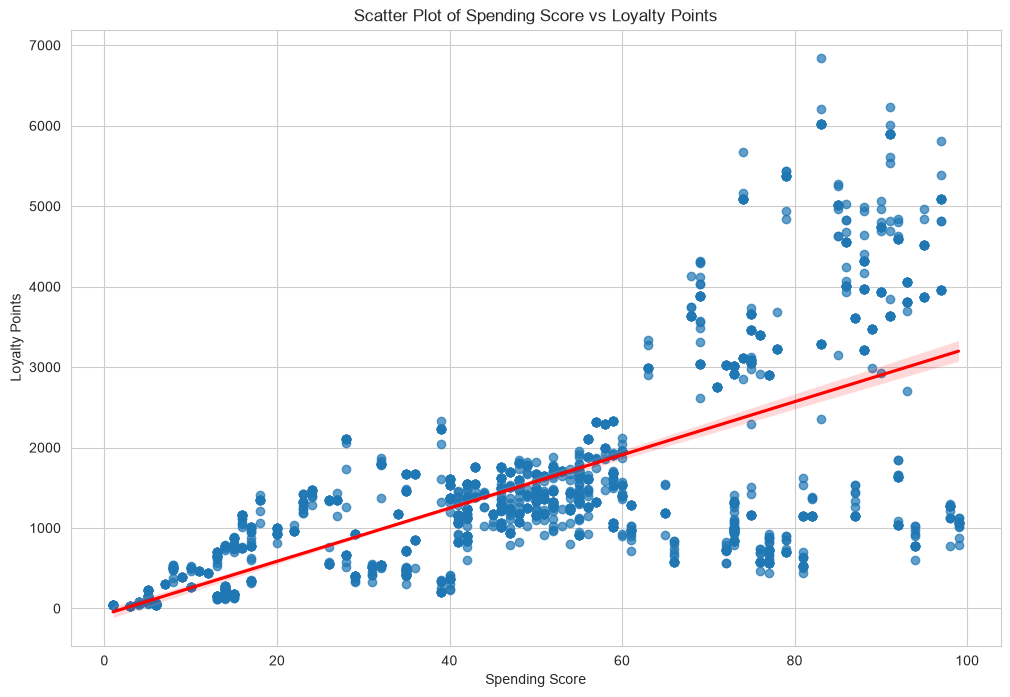

In [17]:
plot_scatter(df, 'spending_score')

There is a positive trend indicating that as spending score increases, loyalty points generally increase. This trend suggests that customers who spend more tend to accumulate more loyalty points. 

However, similar to remuneration, the relationship weakens beyond a spending score of around 60, where loyalty points split into two distinct groups: one with high loyalty points (roughly 3,000 to 6,000) and another with low loyalty points (below 2,000). This suggests that spending score alone may not fully explain how many loyalty points a customer accumulates.

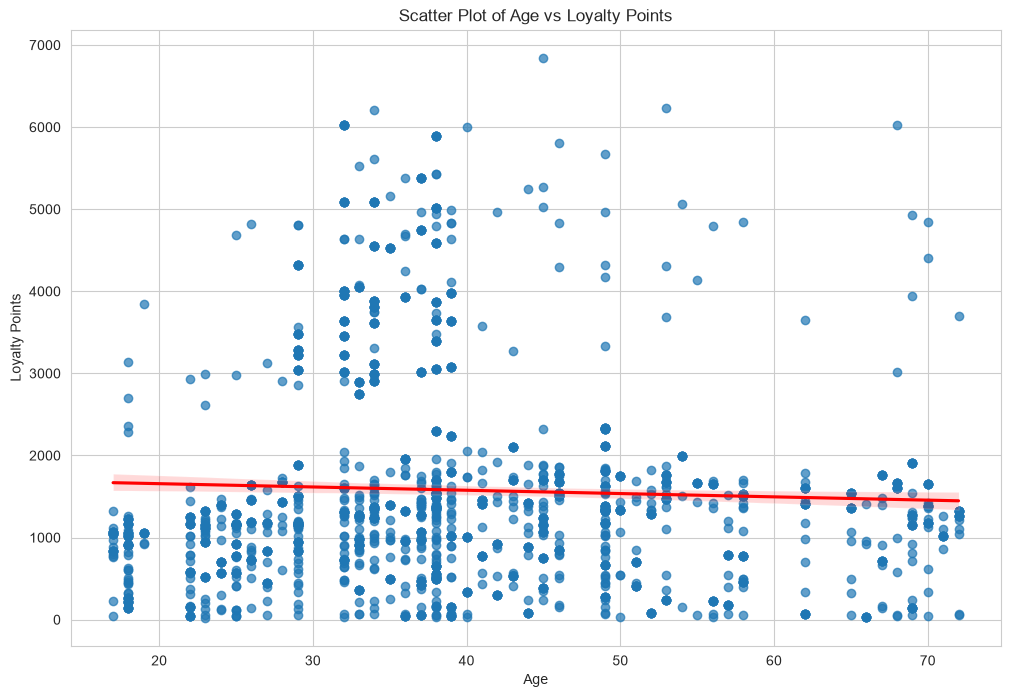

In [18]:
plot_scatter(df, 'age')

There is no clear trend between age and loyalty points, as the regression line is almost flat with a very slight downward slope. This suggests that age on its own has little influence on how many loyalty points a customer accumulates. 

I noticed customers with loyalty points above 3,000 are concentrated between the ages of 30 and 40, indicating that this age group may contain a larger share of highly engaged customers.

## Outlier Analysis

To check for outliers consistently, I applied the IQR rule to every numerical feature. A value is flagged as an outlier if it falls below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. For each feature, I counted the outliers and compared the average `loyalty_points` of outliers against the rest, to see whether the outliers are noise or carry useful information.

In [19]:
num_features = ['age', 'remuneration', 'spending_score']

outlier_summary = []
for col in num_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        'feature': col,
        'lower_bound': lower,
        'upper_bound': upper,
        'n_outliers': is_outlier.sum(),
        'outlier_%': round(is_outlier.sum() / df[col].notna().sum() * 100, 2),
        'mean_loyalty_points_outliers': round(df.loc[is_outlier, 'loyalty_points'].mean(), 1),
        'mean_loyalty_points_others': round(df.loc[~is_outlier & df[col].notna(), 'loyalty_points'].mean(), 1)
    })

pd.DataFrame(outlier_summary)

,feature,lower_bound,upper_bound,n_outliers,outlier_%,mean_loyalty_points_outliers,mean_loyalty_points_others
0,age,-1.00,79.00,0,0.0,NaN,1578.0
1,remuneration,-20.09,114.39,0,0.0,NaN,1578.0
2,spending_score,-29.50,134.50,0,0.0,NaN,1578.0


`age`, `remuneration` and `spending_score` have no outliers, as all their values fall within the expected range. Customer ages range from 17 to 72, remuneration from £12.30k to £112.34k, and spending scores from 1 to 99, all of which are realistic for a retail customer base.

As none of these features contain outliers or data errors, no outlier treatment is required and all values will be kept as they are.

## Correlation Analysis

### Heatmap

In [20]:
# Select relevant columns for correlation analysis
num_vars = df[['age', 'remuneration', 'spending_score', 'loyalty_points']]

#### Spearman Correlation

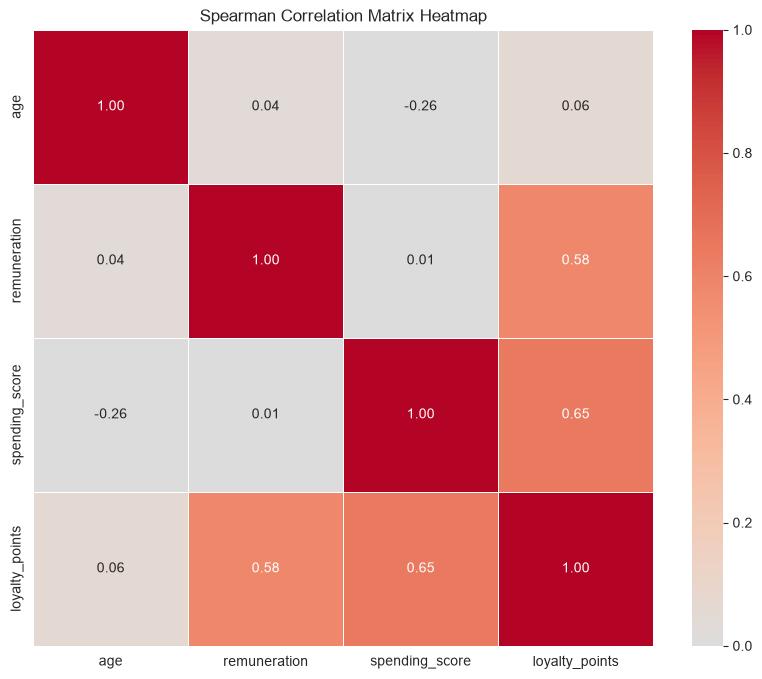

In [21]:
# Compute the Spearman correlation matrix
spearman_corr = num_vars.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

#### Pearson Correlation

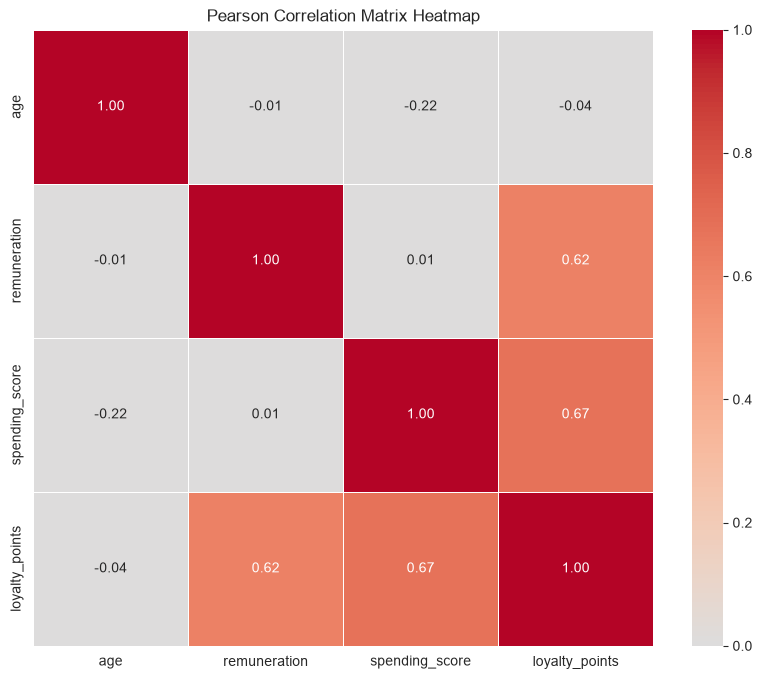

In [22]:
# Compute the Pearson correlation matrix
pearson_corr = num_vars.corr(method='pearson')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Matrix Heatmap')
plt.show()

Pearson correlation was chosen over Spearman correlation for two reasons. First, the next stage of this analysis uses linear regression to model loyalty points, and Pearson correlation measures the strength of linear relationships, which is the same assumption the regression model relies on. Second, Pearson correlation is the standard measure for checking multicollinearity between predictors before building a linear model.

As `loyalty_points` is right-skewed and contains outliers, Spearman correlation was also checked as a robustness test. Both methods produced very similar results (for example, 0.67 vs 0.65 for spending score and 0.62 vs 0.58 for remuneration), confirming that the relationships are not driven by outliers and that Pearson correlation is suitable for this dataset.

## Multicollinearity Check

The Pearson correlation matrix shows that `remuneration` and `spending_score` are almost uncorrelated (0.01), and `age` has only a weak correlation with `spending_score` (-0.22). This suggests that multicollinearity is unlikely to be an issue. To confirm this, the Variance Inflation Factor (VIF) was also calculated, as it can detect multicollinearity involving more than two features. 

In [23]:
X = add_constant(df[['age', 'remuneration', 'spending_score']])
vif = pd.DataFrame({
    'feature': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif[vif['feature'] != 'const'].round(2)

,feature,VIF
1,age,1.05
2,remuneration,1.00
3,spending_score,1.05


All VIF values are close to 1, well below the commonly used threshold of 5, so all three features can be used together in the regression model.

## Data Cleaning

### Correcting Structural Errors

#### Standardising Categorical Labels

In [24]:
# Standardise 'graduate', 'postgraduate' and 'diploma' in the 'education' column
# df['education'] = df['education'].replace({'graduate': 'Graduate', 'postgraduate': 'Postgraduate', 'diploma': 'Diploma'})

### Removing Unnecessary Data

#### Dropping Duplicates

In [25]:
# Check for duplicate records
# print('Duplicate rows:', df.duplicated().sum())

# Identify duplicates
# df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

#### Dropping Irrelevant Features

In [26]:
# Drop irrelevant features
df = df.drop(columns=['language', 'platform'])

### Save Cleaned DataFrame as a CSV File

In [27]:
df.to_csv("data/cleaned_turtle_reviews.csv", index=False)